{'A': 12, 'A2': 30, 'B': 30, 'C': 30, 'D': 30, 'A2m': 60, 'E': 60}
model  epochs  best_epoch  val_mIoU  val_OA  train_loss  val_loss  train_min
    A      12          12     0.395   0.599       1.112     1.161         38
   A2      30          28     0.437   0.631       1.492     1.074         91
    B      30          28     0.415   0.608       1.598     1.140        112
    C      30          28     0.438   0.632       1.494     1.072         88
    D      30          30     0.439   0.635       1.344     1.070         68
  A2m      60          58     0.441   0.633       1.319     1.081        157
    E      60          47     0.489   0.678       1.145     0.988        158


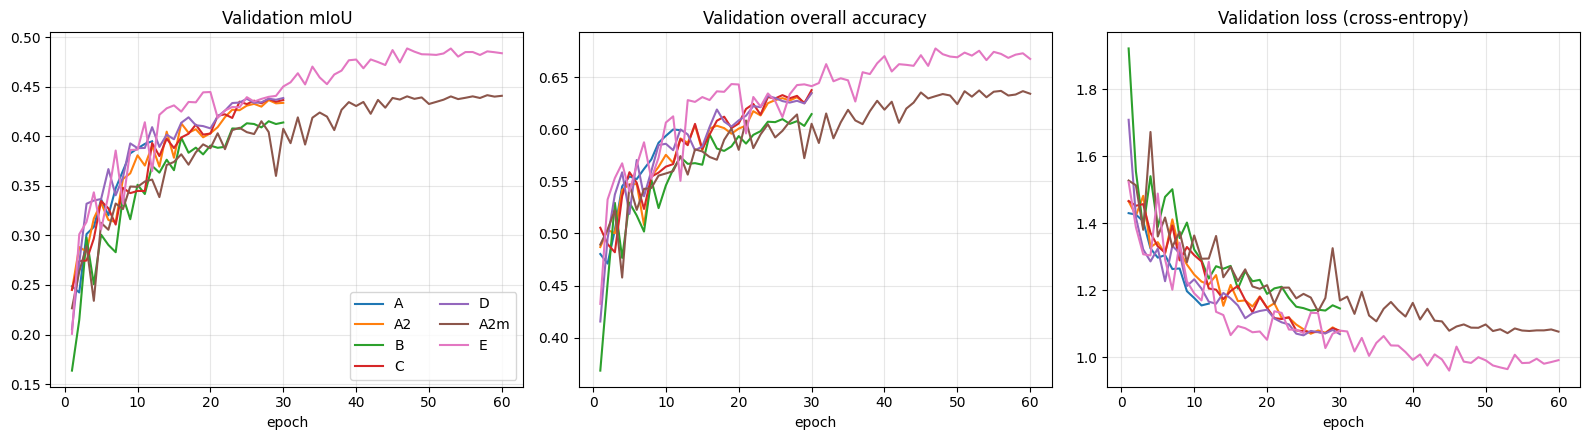

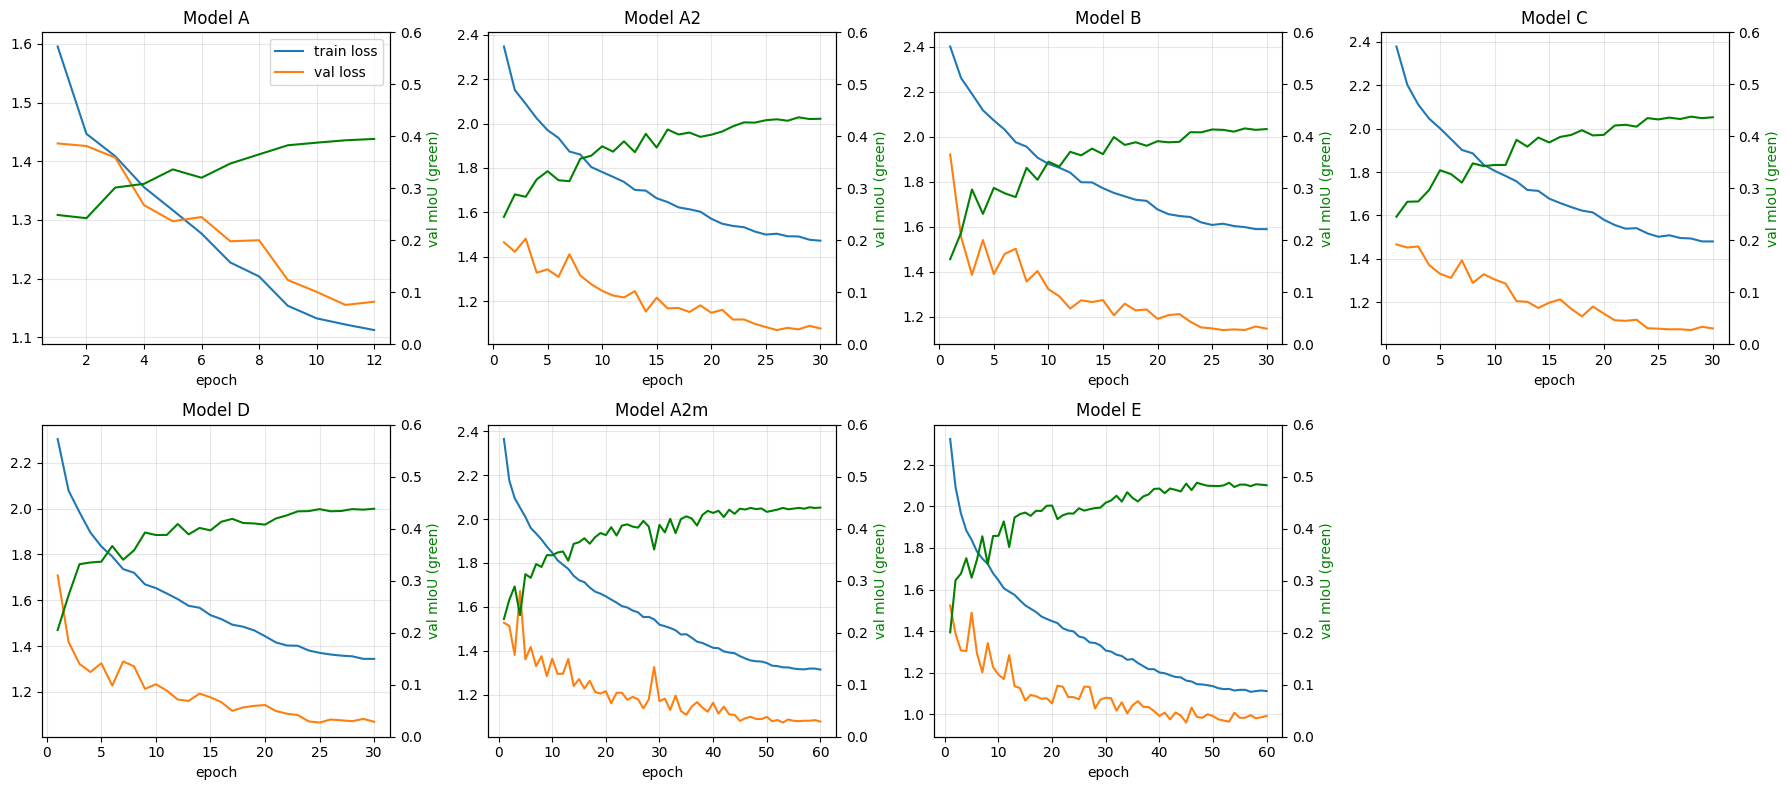

In [1]:
import glob, json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
fs = {os.path.basename(p).split("_")[0]: p for p in glob.glob("/kaggle/input/**/model*_history.json", recursive=True)}
order = ["A", "A2", "B", "C", "D", "A2m", "E"]
H = {k: json.load(open(fs[f"model{k}"])) for k in order}
print({k: len(v) for k, v in H.items()})

rows = []
for k in order:
    h = H[k]; b = max(h, key=lambda r: r["val_miou"])
    rows.append([k, len(h), b["epoch"], round(b["val_miou"], 3), round(b["val_oa"], 3), round(b["train_loss"], 3), round(b["val_loss"], 3), int(sum(r["sec"] for r in h) / 60)])
t = pd.DataFrame(rows, columns=["model", "epochs", "best_epoch", "val_mIoU", "val_OA", "train_loss", "val_loss", "train_min"])
print(t.to_string(index=False)); t.to_csv("/kaggle/working/training_summary.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for k in order:
    e = [r["epoch"] for r in H[k]]
    ax[0].plot(e, [r["val_miou"] for r in H[k]], label=k)
    ax[1].plot(e, [r["val_oa"] for r in H[k]], label=k)
    ax[2].plot(e, [r["val_loss"] for r in H[k]], label=k)
for a, ti in zip(ax, ["Validation mIoU", "Validation overall accuracy", "Validation loss (cross-entropy)"]):
    a.set_title(ti); a.set_xlabel("epoch"); a.grid(alpha=0.3)
ax[0].legend(ncol=2); fig.tight_layout(); fig.savefig("/kaggle/working/curves_comparison.png", dpi=200); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(18, 8)); ax = ax.ravel()
for a, k in zip(ax, order):
    e = [r["epoch"] for r in H[k]]
    a.plot(e, [r["train_loss"] for r in H[k]], label="train loss")
    a.plot(e, [r["val_loss"] for r in H[k]], label="val loss")
    a2 = a.twinx(); a2.plot(e, [r["val_miou"] for r in H[k]], color="green", label="val mIoU"); a2.set_ylim(0, 0.6); a2.set_ylabel("val mIoU (green)", color="green")
    a.set_title(f"Model {k}"); a.set_xlabel("epoch"); a.grid(alpha=0.3)
    if k == "A": a.legend(loc="upper right")
ax[-1].axis("off"); fig.tight_layout(); fig.savefig("/kaggle/working/curves_per_model.png", dpi=200); plt.show()